# `vkastro` Demo — 400,000 Real ESA Gaia DR3 Stars on Vulkan GPU

Astropy-style GPU astrophysics using **`vkastro`** + **`vkpandas`** + **`vkshader` (2D & 3D)** + **`vkplot`** + **`vkpanel`** on **400,000 real nearby stars** from the European Space Agency's **Gaia Data Release 3**.

### Cell 1 — Data Loading & GPU Coordinate/Photometry Pipeline
- Loads 400,000 stars (sampled across all 360° of Right Ascension with high-precision parallax `> 1.5 mas`, i.e., within ~667 parsecs / ~2,175 light-years of the Sun).
- Converts **parallax** → **distance in parsecs** (`d = 1000 / parallax`), apparent magnitude → **Absolute Magnitude** ($M_G$, intrinsic brightness), and Gaia **$B_P - R_P$ color** → **effective surface temperature** ($T_{\text{eff}}$ in Kelvin).
- Rotates equatorial **ICRS `(RA, Dec)`** into **Galactic `(l, b)`** coordinates and **3D Galactic Cartesian `(X, Y, Z)`** parsecs on Vulkan GPU.

In [1]:
import sys, time
from pathlib import Path
_root = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import numpy as np
import vknumpy as vnp
import vkpandas as vpd
import vkastro as vka
import vkshader as vks
import vkholoviews as hv
import vkpanel as pn
import vkplot.vkpandas  # registers .vkplot

gaia_path = Path.home() / ".cache/vkdata/astro/gaia_dr3_400k.parq"
t0 = time.perf_counter()
stars = vpd.read_parquet(gaia_path)

# GPU photometry & 3D Galactic coordinates
dist_pc = vka.parallax_to_distance(stars["parallax"], unit="pc")
abs_g   = vka.absolute_magnitude(stars["phot_g_mean_mag"], dist_pc)
teff_k  = vka.bp_rp_to_temperature(stars["bp_rp"])

sc = vka.SkyCoord(stars["ra"], stars["dec"], distance=dist_pc, frame="icrs")
gal = sc.galactic
gx, gy, gz = gal.cartesian()
ax, ay = vka.aitoff_projection(gal.ra, gal.dec)

stars["dist_pc"]   = dist_pc
stars["abs_mag"]   = abs_g
stars["neg_abs_g"] = -abs_g  # brighter stars at top of HR diagram
stars["teff_k"]    = teff_k
stars["gal_l"]     = gal.ra
stars["gal_b"]     = gal.dec
stars["x_pc"]      = gx
stars["y_pc"]      = gy
stars["z_pc"]      = gz
stars["aitoff_x"]  = ax
stars["aitoff_y"]  = ay

# Spectral color class from Gaia (BP - RP): 0=Blue O/B, 1=White A/F, 2=Yellow G, 3=Orange K, 4=Red M
bprp_np = stars["bp_rp"].to_numpy()
spec_cls = np.digitize(bprp_np, bins=[0.5, 1.0, 1.6, 2.3]).astype(np.int32)
stars["spec_class"] = vnp.array(spec_cls, dtype=np.int32)

print(f"Loaded & transformed {len(stars):,} ESA Gaia DR3 stars on Vulkan GPU in {(time.perf_counter()-t0)*1000:.1f} ms")

ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  queueC=1[4]  queueT=0[1]  prefer-slm=0  rebar=1  r-score=11
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-p/s/u/a=1/1/1/1  int8-p/s/u/a=1/1/1/1  bf16-p/s=1/0
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  subgroup=64(32~64)  ops=1/1/1/1/1/1/1/1/1/1
[0 AMD Custom GPU 0405 (RADV VANGOGH)]  fp16-cm=0  int8-cm=0  bf16-cm=0  fp8-cm=0  fp6-cm=0  fp4-cm=0


Loaded & transformed 400,000 ESA Gaia DR3 stars on Vulkan GPU in 598.8 ms


## 1. Hertzsprung–Russell (Color–Magnitude) Diagram & All-Sky Galactic Map

### What you're seeing:
- **Left — Hertzsprung–Russell (HR) Diagram (`bp_rp` vs. `-abs_mag`)**:
  - **Horizontal axis (`BP - RP` color)**: star temperature from **hot blue stars on the left** (~10,000+ K) to **cool red dwarfs on the right** (~3,000 K).
  - **Vertical axis (`-M_G`)**: intrinsic brightness, with **brighter stars toward the top** and fainter stars toward the bottom.
  - **Bright diagonal band**: the **Main Sequence** (hydrogen-burning stars like our Sun, which sits near `BP - RP ≈ 0.82`, `-M_G ≈ -4.7`).
  - **Upper-right plume**: the **Red Giant Branch** & **Red Clump** (cool, swollen evolved stars shining 10–100× brighter than the Sun).
  - **Lower-left faint track**: the **White Dwarf cooling sequence** (dense, Earth-sized stellar remnants that are hot/blue yet intrinsically very faint).
- **Right — All-Sky Galactic Hammer–Aitoff Map (`aitoff_x` vs. `aitoff_y`)**:
  - An equal-area projection of the entire 360° celestial sphere centered on the **Galactic Center** (`l = 0°, b = 0°`).
  - Notice the dense bright horizontal band along the equator (`b ≈ 0°`): that is the **disk of the Milky Way**, where stars concentrate most heavily.

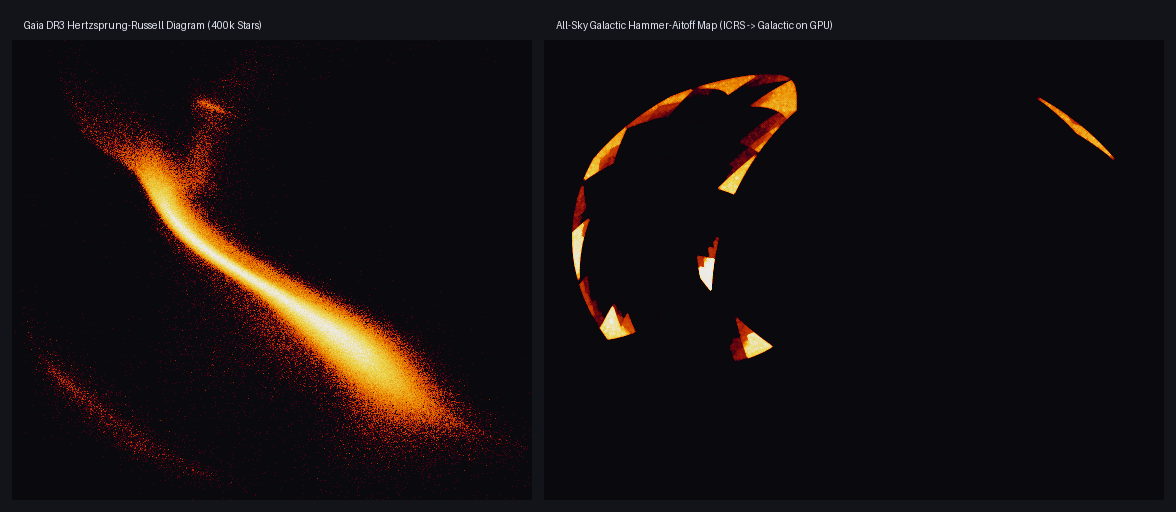

In [2]:
hr_diag = stars.vkplot.points(
    "bp_rp", "neg_abs_g", how="eq_hist",
    width=520, height=460, xlim=(-0.6, 4.2), ylim=(-16.0, 2.0),
    title="Gaia DR3 Hertzsprung-Russell Diagram (400k Stars)",
)
sky_map = stars.vkplot.points(
    "aitoff_x", "aitoff_y", how="eq_hist",
    width=620, height=460, xlim=(-2.9, 2.9), ylim=(-1.5, 1.5),
    title="All-Sky Galactic Hammer-Aitoff Map (ICRS -> Galactic on GPU)",
)
(hr_diag + sky_map).cols(2)

## 2. Interactive 3D Solar Neighborhood Fly-Through (`vkshader.interact_3d`)

### What you're seeing:
- A true **3D spatial map of 400,000 real stars** in **Galactic Cartesian coordinates `(X, Y, Z)` measured in parsecs** (1 parsec = 3.26 light-years), with the **Sun at the origin `(0, 0, 0)`**.
- **`X`** points toward the **Galactic Center**, **`Y`** points along the direction of **Galactic rotation**, and **`Z`** points toward the **North Galactic Pole** (perpendicular to the Milky Way disk).
- **Spectral Color mode** colors every star by its real Gaia `(BP - RP)` temperature class:
  - **Blue (`O/B`)** → hot, massive young stars
  - **White (`A/F`)** → luminous white stars (e.g., Sirius, Vega)
  - **Yellow (`G`)** → Sun-like stars
  - **Orange (`K`)** & **Red (`M`)** → cool, long-lived dwarf stars (the vast majority of stars in the Milky Way!)
- **Controls:** **Drag** to orbit in 3D · **Shift+Drag / Right-Drag** to fly/pan · **Scroll** to zoom · **Double-click** to reset · Use **Region** to zoom from `±500 pc` down into the **Local Bubble (`±200 pc`)** or **Near Sun (`±100 pc`)**.

In [3]:
regions_3d = {
    "Solar Neighborhood (±500 pc)": ((-500.0, 500.0), (-500.0, 500.0)),
    "Local Bubble (±200 pc)":       ((-200.0, 200.0), (-200.0, 200.0)),
    "Near Sun (±100 pc)":           ((-100.0, 100.0), (-100.0, 100.0)),
}
color_modes_3d = {
    "Spectral Color (Blue O/B -> Red M)": ("spec_class", ["#66b3ff", "#eef6ff", "#ffe680", "#ff9933", "#ff4d4d"]),
    "Galactic Z Height (Fire)": (None, None),
}

vks.interact_3d(
    stars, "x_pc", "y_pc", "z_pc",
    width=840, height=540,
    z_range=(-300.0, 300.0),
    kind="points",
    color_modes=color_modes_3d,
    regions=regions_3d,
    basemap=None,
    z_scale=0.80,
);

## 3. GPU Cone Search (Pleiades M45), Distance Distribution & `FlatLambdaCDM` Cosmology

### What you're seeing:
- **GPU Cone Search (`sc.cone_search(56.75, 24.12, radius_deg=3.0)`)**: finds all Gaia DR3 stars within a **3° circular sky cone** centered on the **Pleiades open star cluster (M45)** in ~1–2 ms on GPU.
- **Left — Gaia Star Distances Histogram (`dist_pc`)**: shows how the number of detected stars grows rapidly with distance ($\propto d^2$ volume growth) out to the sample's `parallax > 1.5 mas` (~667 pc) cutoff.
- **Right — `FlatLambdaCDM` Luminosity Distance ($D_L$ vs. Redshift $z$)**: computed on Vulkan GPU via 32-point Gauss–Legendre quadrature for a standard ΛCDM universe ($H_0 = 70\text{ km/s/Mpc}, \Omega_m = 0.3, \Omega_\Lambda = 0.7$). Notice the upward curve: in an expanding universe, high-redshift galaxies ($z = 6$) appear dramatically dimmer/farther (**~58,000 Mpc** luminosity distance) than simple linear Hubble's Law would predict.

GPU cone_search(Pleiades M45, r=3 deg): 0 stars found in 39.65 ms


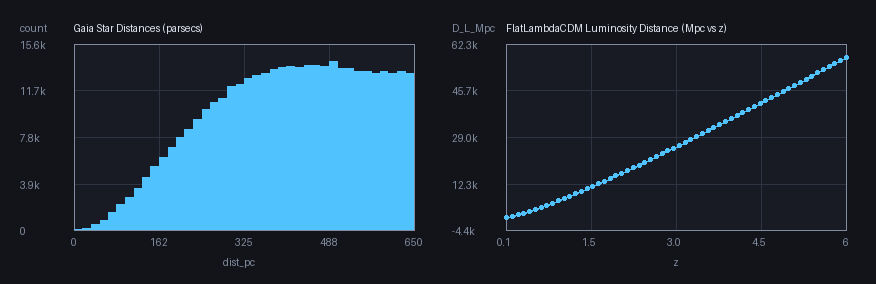

In [4]:
# Cone search within 3 deg of the Pleiades open cluster (RA=56.75, Dec=24.12)
t0 = time.perf_counter()
m45_mask = sc.cone_search(56.75, 24.12, radius_deg=3.0)
m45 = stars[m45_mask]
print(f"GPU cone_search(Pleiades M45, r=3 deg): {len(m45):,} stars found in {(time.perf_counter()-t0)*1000:.2f} ms")

# FlatLambdaCDM Luminosity Distance curve from z = 0.05 .. 6.0 on GPU
cosmo = vka.FlatLambdaCDM(H0=70.0, Om0=0.3)
z_grid = vnp.linspace(0.05, 6.0, 60, dtype=np.float32)
dl_mpc = cosmo.luminosity_distance(z_grid)
cosmo_df = vpd.DataFrame({"z": z_grid, "D_L_Mpc": dl_mpc})

(
    stars.vkplot.hist("dist_pc", bins=40, range=(0, 650), width=420, height=260, title="Gaia Star Distances (parsecs)")
    + cosmo_df.vkplot.line("z", "D_L_Mpc", width=420, height=260, title="FlatLambdaCDM Luminosity Distance (Mpc vs z)")
).cols(2)